# Cookie Cats A/B Test 

**Problem:** In the game Cookie Cats, a "gate" blocks the player until they wait or pay.
- `gate_30` = gate at level 30 (original, called *control*)
- `gate_40` = gate moved to level 40 (the *test*)

**Question:** Does moving the gate to level 40 change how many players come back (retention)?

**Columns:** `userid`, `version`, `sum_gamerounds`, `retention_1` (came back after 1 day?), `retention_7` (came back after 7 days?)

## Step 1: Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

## Step 2: Load the data

In [ ]:
df = pd.read_csv("cookie_cats.csv")   
df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## Step 3: Check the data

In [3]:
print("Rows and columns:", df.shape)

Rows and columns: (90189, 5)


In [4]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64


In [5]:
print("Duplicate users:", df["userid"].duplicated().sum())

Duplicate users: 0


In [6]:
print(df["version"].value_counts())

version
gate_40    45489
gate_30    44700
Name: count, dtype: int64


Both groups have a similar number of players (about 45,000 each), so the comparison is fair.

## Step 4: Remove the outlier
An outlier is a value far away from the rest. Let's see the biggest values of `sum_gamerounds`.

In [7]:
df.sort_values("sum_gamerounds", ascending=False).head(5)

,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,False,True
7912,871500,gate_30,2961,True,True
29417,3271615,gate_40,2640,True,False
43671,4832608,gate_30,2438,True,True
48188,5346171,gate_40,2294,True,True


One player has **49,854** rounds, but the next highest is only **2,961**. That is not realistic (probably a bot or an error), so we remove only that player.

In [8]:
df = df[df["sum_gamerounds"] < 10000]
print("Rows left:", len(df))

Rows left: 90188


## Step 5: Look at average results per group

In [9]:
df.groupby("version")[["retention_1", "retention_7", "sum_gamerounds"]].mean()

,retention_1,retention_7,sum_gamerounds
version,,,
gate_30,0.448198,0.190183,51.342111
gate_40,0.442283,0.182000,51.298776


`gate_30` looks slightly better. But is the difference real, or just luck? We need a statistical test.

## Step 6: Test 1-day retention
`retention_1` is True/False, so we use a **two-proportion z-test**.

- **H0:** retention is the same in both groups
- **H1:** retention is different

If **p-value < 0.05**, we reject H0 (the difference is real).

In [10]:
yes = df.groupby("version")["retention_1"].sum()      # players who came back
total = df.groupby("version")["retention_1"].count()  # all players
print(yes / total)

version
gate_30    0.448198
gate_40    0.442283
Name: retention_1, dtype: float64


In [11]:
z, p = proportions_ztest(yes.values, total.values)
print("p-value:", round(p, 4))

p-value: 0.0739


In [12]:
if p < 0.05:
    print("Real difference")
else:
    print("No real difference")

No real difference


## Step 7: Test 7-day retention (same steps)

In [13]:
yes = df.groupby("version")["retention_7"].sum()
total = df.groupby("version")["retention_7"].count()
print(yes / total)

version
gate_30    0.190183
gate_40    0.182000
Name: retention_7, dtype: float64


In [14]:
z, p = proportions_ztest(yes.values, total.values)
print("p-value:", round(p, 4))

p-value: 0.0016


In [15]:
if p < 0.05:
    print("Real difference")
else:
    print("No real difference")

Real difference


For 7-day retention, `gate_30` is about **0.8 percentage points higher**, and p-value is about 0.002, so this is a **real difference**.

## Step 8: Chart of retention

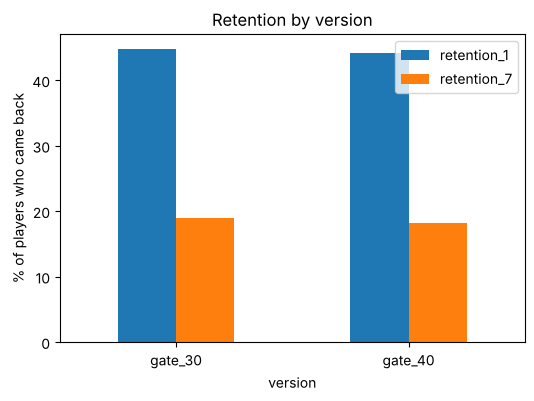

In [16]:
rates = df.groupby("version")[["retention_1", "retention_7"]].mean() * 100
rates.plot(kind="bar", figsize=(6, 4))
plt.ylabel("% of players who came back")
plt.title("Retention by version")
plt.xticks(rotation=0)
plt.show()

## Step 9: Test game rounds
Game rounds are very skewed (a few players play a lot), so we use the **Mann-Whitney U test** instead of a t-test.

In [17]:
rounds_30 = df[df["version"] == "gate_30"]["sum_gamerounds"]
rounds_40 = df[df["version"] == "gate_40"]["sum_gamerounds"]
print("Median rounds gate_30:", rounds_30.median())
print("Median rounds gate_40:", rounds_40.median())

Median rounds gate_30: 17.0
Median rounds gate_40: 16.0


In [18]:
u, p = stats.mannwhitneyu(rounds_30, rounds_40)
print("p-value:", round(p, 4))

p-value: 0.0509


The p-value is about 0.05, which is borderline. So there is **no clear difference** in rounds played. We rely on retention for the decision.

## Step 10: Double-check with a bootstrap
The bootstrap re-draws players (with replacement) many times to see how much the 7-day retention difference changes by chance.

In [19]:
np.random.seed(42)   # makes results repeatable
a = df[df["version"] == "gate_30"]["retention_7"].astype(int).values
b = df[df["version"] == "gate_40"]["retention_7"].astype(int).values

In [20]:
diffs = []
for i in range(2000):
    sample_a = np.random.choice(a, size=len(a))
    sample_b = np.random.choice(b, size=len(b))
    diffs.append((sample_a.mean() - sample_b.mean()) * 100)
diffs = np.array(diffs)

In [21]:
print("Average difference (pp):", round(diffs.mean(), 2))
print("95% interval (pp):", round(np.percentile(diffs, 2.5), 2), "to", round(np.percentile(diffs, 97.5), 2))
print("gate_30 better in", round((diffs > 0).mean() * 100, 1), "% of re-draws")

Average difference (pp): 0.82
95% interval (pp): 0.33 to 1.28
gate_30 better in 100.0 % of re-draws


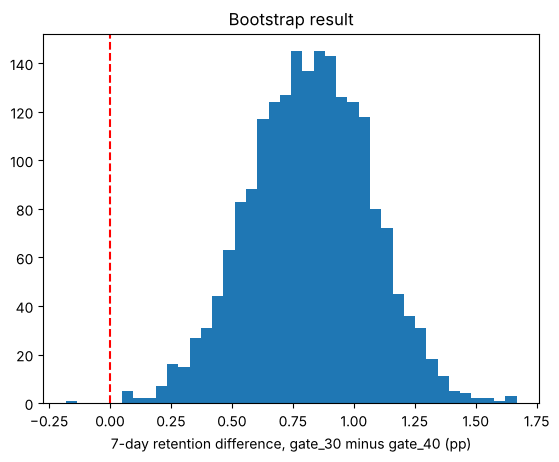

In [22]:
plt.hist(diffs, bins=40)
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("7-day retention difference, gate_30 minus gate_40 (pp)")
plt.title("Bootstrap result")
plt.show()

The whole 95% interval is above 0, so `gate_30` really is better on 7-day retention. This agrees with the z-test.

## Step 11: Sample size and power
**Power** is the chance a test detects a real difference. A common target is 80%. Tiny differences like ours need a lot of players, so let's check if our test was big enough.

In [23]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

rate_30 = a.mean()
rate_40 = b.mean()
effect = proportion_effectsize(rate_30, rate_40)

In [24]:
needed = NormalIndPower().solve_power(effect_size=effect, alpha=0.05, power=0.8)
print("Players needed per group for 80% power:", int(needed))
print("Players we had in gate_30:", len(a))

Players needed per group for 80% power: 35501
Players we had in gate_30: 44699


In [25]:
power = NormalIndPower().solve_power(effect_size=effect, nobs1=len(a), alpha=0.05, ratio=len(b) / len(a))
print("Power of our test:", round(power * 100, 1), "%")

Power of our test: 88.4 %


We had more players than needed, so the test was large enough to trust the 7-day result. 
The effect itself is still small (under 1 percentage point).

## Step 12: Retention by activity level
Let's group players by how much they played, and compare **rates** (not counts, because group sizes differ).

In [26]:
bins = [-1, 0, 9, 29, 49, 99, 199, 100000]
names = ["0", "1-9", "10-29", "30-49", "50-99", "100-199", "200+"]
df["activity"] = pd.cut(df["sum_gamerounds"], bins=bins, labels=names)

In [27]:
table = df.pivot_table(index="activity", columns="version",
                       values="retention_7", aggfunc="mean", observed=True)
table

version,gate_30,gate_40
activity,,
0,0.008260,0.006320
1-9,0.018056,0.018247
10-29,0.081096,0.073383
30-49,0.184532,0.173749
50-99,0.375315,0.328899
100-199,0.609212,0.611606
200+,0.848935,0.848657


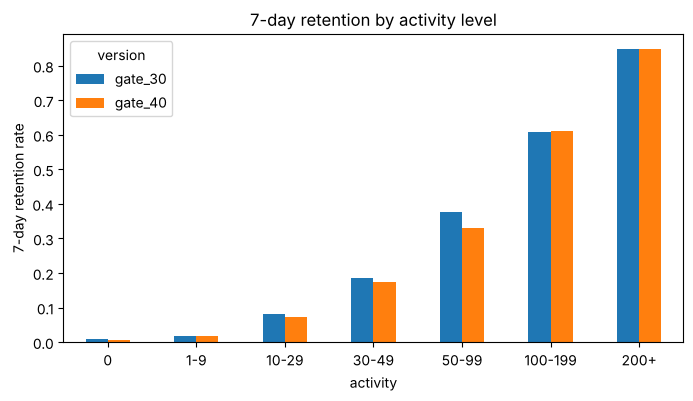

In [28]:
table.plot(kind="bar", figsize=(8, 4))
plt.ylabel("7-day retention rate")
plt.title("7-day retention by activity level")
plt.xticks(rotation=0)
plt.show()

This is only a descriptive look. Players with 30 to 99 rounds (near the gate) show the biggest gap in favor of `gate_30`.

## Step 13: Conclusion

| Metric | gate_30 | gate_40 | Real difference? |
|---|---|---|---|
| 1-day retention | 44.8% | 44.2% | No (p about 0.07) |
| 7-day retention | 19.0% | 18.2% | **Yes** (p about 0.002) |
| Game rounds | similar | similar | No (borderline) |

**Recommendation: keep the gate at level 30.** Moving it to level 40 does not help and slightly lowers 7-day retention.

**Limitations:** we only have day-1 and day-7 data and no revenue data, and the effect is small (under 1 percentage point).